# QSV2G — Complete Reference Prototype & Experiments

**Protocol source:** `QSV2G_main8_SectionIV_Revised.tex`, Section IV (revision SHA-256 in the final manifest).  
**Scope:** EV/CS Bell-pair registration simulation; authority-backed cross-domain HMAC; ML-KEM-768 + HKDF-SHA256 session establishment; exact three-qutrit `(2,3)` QSS; authority decisions and authenticated commitments; ML-DSA-65 two-authority tokens; AES-256-GCM directional traffic protection; EV verification; energy execution and termination; fault tests, correctness checks, noise simulation and timings.

> **Scientific boundaries.** This is a **research simulator**, not a secure physical implementation. The three-qutrit scheme shares **classical ternary secret symbols encoded as quantum states**. State-consistency tests and public commitments do **not** prove malicious-secure verifiable QSS. The token contains *signed attestations* of reconstruction, not a publicly verifiable quantum proof. UC-A and UC-B are required online in this protocol, even when QSS shares of another pair are used. OpenSSL backend timings include CLI/subprocess overhead. In-memory state, authenticated authority transport, trusted registration provisioning, quantum memory, and metering are simulator assumptions, not measured deployment properties.

## Run on Kaggle

1. Create a Kaggle notebook (CPU is sufficient). In **Notebook Settings**, enable **Internet** for the first run so the required `pqcrypto` package can install if needed; enable saving outputs.
2. Upload this notebook and **Run All** from the first cell. The notebook installs `pqcrypto` when running on Kaggle and also attempts optional `qiskit` / `pennylane` installs for independent Bell-state checks. Actual KEM and signature primitives are mandatory, not replaced by X25519/Ed25519.
3. At the end, download `qsv2g_results.zip` from `/kaggle/working/`. Share this ZIP or its CSV/JSON contents to review the actual experimental results.
4. For research claims, rerun with multiple seeds/conditions and include hardware, framework versions, and channel/noise model. Do **not** report model or simulator speed as real quantum-network latency.

The first local run uses real standardized post-quantum cryptography from OpenSSL 3.5+ if `pqcrypto` is unavailable. This notebook contains all core implementation code and is self-contained.


## 0. Environment and standardized crypto backend

In [1]:
# Kaggle dependency setup. No cryptographic fallback to non-PQC algorithms.
import os, sys, subprocess, importlib.util, platform
IN_KAGGLE = os.path.exists('/kaggle/working')
if IN_KAGGLE:
    modules = [('pqcrypto','pqcrypto>=1.0.0'), ('qiskit','qiskit>=1.0'), ('pennylane','pennylane>=0.40')]
    missing = [pkg for module,pkg in modules if importlib.util.find_spec(module) is None]
    if missing:
        print('Installing on Kaggle:',missing)
        subprocess.run([sys.executable,'-m','pip','install','--quiet',*missing],check=True)
else:
    print('Local runtime: using available libraries; optional Qiskit/PennyLane checks skip if unavailable.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
RESULTS = Path('/kaggle/working/qsv2g_results' if IN_KAGGLE else '/mnt/data/qsv2g_notebook_results')
RESULTS.mkdir(parents=True,exist_ok=True)
print('Python',sys.version.split()[0], '| NumPy',np.__version__, '| Results',RESULTS)


Local runtime: using available libraries; optional Qiskit/PennyLane checks skip if unavailable.


Python 3.13.5 | NumPy 2.3.5 | Results /mnt/data/qsv2g_notebook_results


## 1. Complete protocol implementation
Self-contained: this cell implements Bell-state transport, qutrit QSS, actual PQC algorithms, authenticated session messages, threshold token and energy execution. The Python source is embedded in the notebook.

In [2]:
"""QSV2G Section IV reference prototype (research simulation, NOT deployed secure system).
Source: QSV2G_main8_SectionIV_Revised.tex.
Quantum: exact 27D three-qutrit statevectors with sampled pair measurements.
PQC: actual ML-KEM-768 / ML-DSA-65 via pqcrypto OR OpenSSL >= 3.5.
This is not malicious-secure verifiable QSS. Authenticated channels, secure enrollment,
quantum memory and two-authority honesty are simulation assumptions.
"""
from __future__ import annotations
import base64
import hashlib
import hmac
import json
import math
import os
import secrets
import shutil
import subprocess
import tempfile
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any
import numpy as np
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

LABEL = 'QSV2G-REFERENCE-2026'
AUTHORITIES = ('A','B','C')
SLOT = {'A':0,'B':1,'C':2}

class ProtocolAbort(Exception):
    pass

def require(condition, explanation):
    if not condition:
        raise ProtocolAbort(explanation)

def json_obj(o):
    if isinstance(o, bytes): return {'__type__':'bytes', 'base64':base64.b64encode(o).decode('ascii')}
    if isinstance(o, tuple): return {'__type__':'tuple', 'items':[json_obj(x) for x in o]}
    if isinstance(o, list): return [json_obj(x) for x in o]
    if isinstance(o, dict): return {str(k):json_obj(v) for k,v in sorted(o.items())}
    if isinstance(o, (str,int,bool)) or o is None: return o
    raise TypeError(f'Unsupported field {type(o).__name__}: floating-point values are intentionally disallowed')

def canon(x):
    return json.dumps(json_obj(x), sort_keys=True, separators=(',',':'), ensure_ascii=False).encode('utf-8')

def parse_canon(raw):
    def restore(x):
        if isinstance(x, list): return [restore(y) for y in x]
        if isinstance(x, dict):
            if x.get('__type__')=='bytes' and set(x)=={'__type__','base64'}:
                return base64.b64decode(x['base64'],validate=True)
            if x.get('__type__')=='tuple' and set(x)=={'__type__','items'}:
                return tuple(restore(y) for y in x['items'])
            return {k:restore(v) for k,v in x.items()}
        return x
    return restore(json.loads(raw.decode('utf-8')))

def encode(*fields):
    """Fixed ordering, deterministic, typed-length-separated encoding."""
    out=bytearray()
    for f in fields:
        chunk=canon(f)
        out += len(chunk).to_bytes(4,'big')+chunk
    return bytes(out)

def H(*fields): return hashlib.sha256(encode(*fields)).digest()
def mac(k, *fields): return hmac.new(k, encode(*fields), 'sha256').digest()
def ct_eq(a,b): return hmac.compare_digest(a,b)
def hkdf_extract(salt, ikm): return hmac.new(salt, ikm, 'sha256').digest()
def hkdf_expand(prk, info, n=32):
    out=b''; t=b''
    for i in range(1,math.ceil(n/32)+1):
        t=hmac.new(prk, t+info+bytes([i]), 'sha256').digest(); out+=t
    return out[:n]

def digest_for(label, *items): return H(label, *items)

# ---- Quantum statevectors ----
I2=np.eye(2,dtype=np.complex128)
X2=np.array([[0,1],[1,0]],complex)
Z2=np.diag([1,-1]).astype(complex)
H2=np.array([[1,1],[1,-1]],complex)/np.sqrt(2)
CNOT=np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]],complex)
BELL=np.array([1,0,0,1],complex)/np.sqrt(2)

def dense_encode_decode(two_bits):
    a,b=two_bits
    state=np.kron(np.linalg.matrix_power(Z2,a)@np.linalg.matrix_power(X2,b),I2)@BELL
    final=np.kron(H2,I2)@CNOT@state
    probabilities=np.abs(final)**2
    idx=int(np.argmax(probabilities))
    require(np.isclose(probabilities[idx],1,atol=1e-12),'Bell decoding failure')
    return (idx//2,idx%2)

def dense_transport_tag(tag):
    recovered=bytearray()
    bits=''.join(f'{byte:08b}' for byte in tag)
    out=''
    for k in range(0,len(bits),2):
        aa,bb=dense_encode_decode((int(bits[k]),int(bits[k+1])))
        out+=str(aa)+str(bb)
    recovered.extend(int(out[j:j+8],2) for j in range(0,len(out),8))
    return bytes(recovered)

OMEGA=np.exp(2j*np.pi/3)
X3=np.roll(np.eye(3,dtype=complex),1,axis=0)
Z3=np.diag([OMEGA**j for j in range(3)])


def qss_state(s):
    """|psi(s)> = sum_r |r,r+s,r+2s> /sqrt(3)."""
    require(s in (0,1,2),'Invalid trit')
    state=np.zeros((3,3,3),dtype=complex)
    for r in range(3): state[r,(r+s)%3,(r+2*s)%3]=1/np.sqrt(3)
    return state

def reduced_density(psi, kept):
    moved=np.moveaxis(psi,kept,0).reshape(3,-1)
    return moved@moved.conj().T

def measure_pair(psi, pair, rng, x_fault=False):
    """Sample joint computational measurement of two shares from a 3-qutrit statevector.
    x_fault applies a qutrit-X error to the SECOND selected share before measuring.
    """
    u,v=[SLOT[p] for p in pair]
    state=np.moveaxis(psi,(u,v),(0,1))
    probs=(np.abs(state)**2).sum(axis=2).reshape(-1)
    idx=int(rng.choice(9,p=probs/probs.sum()))
    xu,xv=divmod(idx,3)
    if x_fault: xv=(xv+1)%3
    return xu,xv

def recover_symbol(pair,xu,xv):
    denom=(SLOT[pair[1]]-SLOT[pair[0]])%3
    return ((xv-xu)*pow(denom,-1,3))%3

def qss_consistency():
    Xa=np.kron(np.kron(X3,X3),X3)
    Za=np.kron(np.kron(Z3,Z3),Z3)
    vals=[]
    for s in range(3):
        psi=qss_state(s)
        psi_flat=psi.reshape(-1)
        vals.append({
            's':s,
            'norm':float(np.vdot(psi_flat,psi_flat).real),
            'x_stabilizer_error':float(np.linalg.norm(Xa@psi_flat-psi_flat)),
            'z_stabilizer_error':float(np.linalg.norm(Za@psi_flat-psi_flat)),
            'one_share_distances':[float(np.linalg.norm(reduced_density(psi,b)-np.eye(3)/3)) for b in range(3)],
        })
    return vals

# ---- Actual standardized post-quantum cryptography, no silent fallbacks ----
class PQCrypto:
    def __init__(self):
        self.kind=None
        try:
            from pqcrypto.kem import ml_kem_768
            from pqcrypto.sign import ml_dsa_65
            self.kem=ml_kem_768; self.sig=ml_dsa_65
            self.kind='pqcrypto native ML-KEM-768 + ML-DSA-65'
        except (ImportError,ModuleNotFoundError):
            exe=shutil.which('openssl')
            if exe:
                test=subprocess.run([exe,'list','-kem-algorithms'],capture_output=True,text=True)
                sig=subprocess.run([exe,'list','-signature-algorithms'],capture_output=True,text=True)
                if 'ML-KEM-768' in test.stdout and 'ML-DSA-65' in sig.stdout:
                    self.kind='OpenSSL 3.5+ ML-KEM-768 + ML-DSA-65 (subprocess)'
                    self.openssl=exe
            if self.kind is None:
                raise RuntimeError('Real ML-KEM-768/ML-DSA-65 unavailable. Enable Kaggle Internet and pip install pqcrypto. No classical substitute will be used.')
    def _openssl_call(self, arguments, input_files=None, output_files=()):
        with tempfile.TemporaryDirectory(prefix='qsv2g_pqc_') as folder:
            root=Path(folder)
            for name,data in (input_files or {}).items(): (root/name).write_bytes(data)
            argv=[self.openssl]+[str(root/(v[1:])) if isinstance(v,str) and v.startswith('@') else str(v) for v in arguments]
            p=subprocess.run(argv, stdout=subprocess.PIPE, stderr=subprocess.PIPE, cwd=root, timeout=30)
            if p.returncode:
                raise RuntimeError('OpenSSL cryptographic call failed: '+p.stderr.decode('utf-8',errors='replace')[:500])
            return (p.stdout, *[(root/x).read_bytes() for x in output_files])
    def kem_keygen(self):
        if self.kind.startswith('pqcrypto'):
            pub,priv=(self.kem.keygen() if hasattr(self.kem,'keygen') else self.kem.generate_keypair()); return pub,priv
        # key generation and public-key extraction share one temporary directory
        with tempfile.TemporaryDirectory(prefix='qsv2g_kem_') as d:
            sk=Path(d)/'sk.pem'; pk=Path(d)/'pk.pem'
            subprocess.run([self.openssl,'genpkey','-algorithm','ML-KEM-768','-out',str(sk)],check=True,capture_output=True)
            subprocess.run([self.openssl,'pkey','-in',str(sk),'-pubout','-out',str(pk)],check=True,capture_output=True)
            return pk.read_bytes(), sk.read_bytes()
    def encaps(self,pub):
        if self.kind.startswith('pqcrypto'):
            return self.kem.encaps(pub) if hasattr(self.kem,'encaps') else self.kem.encrypt(pub)
        _,ct,ss=self._openssl_call(['pkeyutl','-encap','-pubin','-inkey','@pk','-out','@ct','-secret','@ss'], {'pk':pub},('ct','ss'))
        return ct,ss
    def decaps(self,priv,ct):
        if self.kind.startswith('pqcrypto'):
            return self.kem.decaps(priv,ct) if hasattr(self.kem,'decaps') else self.kem.decrypt(priv,ct)
        _,ss=self._openssl_call(['pkeyutl','-decap','-inkey','@sk','-in','@ct','-secret','@ss'],{'sk':priv,'ct':ct},('ss',))
        return ss
    def sig_keygen(self):
        if self.kind.startswith('pqcrypto'):
            return self.sig.keygen() if hasattr(self.sig,'keygen') else self.sig.generate_keypair()
        with tempfile.TemporaryDirectory(prefix='qsv2g_sig_') as d:
            sk=Path(d)/'sk.pem'; pk=Path(d)/'pk.pem'
            subprocess.run([self.openssl,'genpkey','-algorithm','ML-DSA-65','-out',str(sk)],check=True,capture_output=True)
            subprocess.run([self.openssl,'pkey','-in',str(sk),'-pubout','-out',str(pk)],check=True,capture_output=True)
            return pk.read_bytes(),sk.read_bytes()
    def sign(self,priv,msg):
        if self.kind.startswith('pqcrypto'):
            return self.sig.sign(priv,msg)
        _,sig=self._openssl_call(['pkeyutl','-sign','-inkey','@sk','-in','@msg','-out','@sig'],{'sk':priv,'msg':msg},('sig',))
        return sig
    def verify(self,pub,msg,sig):
        if self.kind.startswith('pqcrypto'):
            try:
                result=self.sig.verify(pub,msg,sig)
                return result is None or result is True
            except Exception: return False  # InvalidSignatureError from pqcrypto 1.x, ValueError on older versions
        try:
            self._openssl_call(['pkeyutl','-verify','-pubin','-inkey','@pk','-in','@msg','-sigfile','@sig'],{'pk':pub,'msg':msg,'sig':sig})
            return True
        except RuntimeError: return False

@dataclass
class Traffic:
    key:bytes
    send_counter:int=0
    seen:set=field(default_factory=set)
    def encrypt(self,pt:bytes,ad:bytes):
        require(self.send_counter<2**96-1,'AES-GCM counter exhaustion')
        nonce=self.send_counter.to_bytes(12,'big'); self.send_counter+=1
        ct=AESGCM(self.key).encrypt(nonce,pt,ad)
        return {'nonce':nonce,'ciphertext':ct}
    def decrypt(self,pkt,ad):
        nonce=pkt['nonce']
        require(len(nonce)==12 and nonce not in self.seen,'duplicate or malformed AEAD nonce')
        try: pt=AESGCM(self.key).decrypt(nonce,pkt['ciphertext'],ad)
        except Exception as e: raise ProtocolAbort('AEAD authentication failure') from e
        self.seen.add(nonce)
        return pt

@dataclass
class QSSResource:
    nu:str
    dealer_secrets:dict
    states:dict
    commitments:dict
    state:str='UNUSED'
    lock:tuple|None=None
    def reserve(self,ac,pair):
        require(self.state=='UNUSED','QSS resource already reserved or consumed')
        require(len(set(pair))==2 and all(a in AUTHORITIES for a in pair),'pair invalid')
        self.state='RESERVED'; self.lock=(ac,tuple(pair))
    def reconstruct(self,ac,pair,rng,tamper=False):
        require(self.state=='RESERVED' and self.lock==(ac,tuple(pair)),'QSS reservation mismatch')
        recovered={a:[] for a in AUTHORITIES}
        try:
            for dealer in AUTHORITIES:
                for k,psi in enumerate(self.states[dealer]):
                    xu,xv=measure_pair(psi,pair,rng,x_fault=(tamper and dealer=='A' and k==0))
                    recovered[dealer].append(recover_symbol(pair,xu,xv))
            for dealer in AUTHORITIES:
                expected=H('QSV2G-QSS-COM',dealer,self.nu,recovered[dealer])
                require(ct_eq(expected,self.commitments[dealer]),'QSS reconstructed commitment mismatch')
            combined=[sum(recovered[a][k] for a in AUTHORITIES)%3 for k in range(len(recovered['A']))]
            return combined
        finally:
            self.state='CONSUMED'
            self.states.clear()  # simulated irreversible measurement / erasure

def new_qss_resource(L=162,rng=None):
    rng=rng or np.random.default_rng(2026)
    nu=secrets.token_hex(12)
    dealer_secrets={a:[secrets.randbelow(3) for _ in range(L)] for a in AUTHORITIES}
    states={a:[qss_state(s) for s in dealer_secrets[a]] for a in AUTHORITIES}
    commits={a:H('QSV2G-QSS-COM',a,nu,dealer_secrets[a]) for a in AUTHORITIES}
    return QSSResource(nu,dealer_secrets,states,commits)

class QSV2G:
    """Single-session strict reference implementation with explicit trusted authority simulation."""
    def __init__(self,crypto=None, seed=2026,L=162,available=None):
        self.pqc=crypto or PQCrypto(); self.rng=np.random.default_rng(seed)
        self.available=set(available if available is not None else AUTHORITIES)
        self.L=L; self.log=[]; self.replay_ev=set(); self.replay_cs=set(); self.executed=set()
        self.wire_bytes={}  # Message sizes include ciphertext/tag and 96-bit GCM nonce; exclude implied AAD.
        self.reg_ev=secrets.token_bytes(32); self.reg_cs=secrets.token_bytes(32)
        self.pid_master=secrets.token_bytes(32); self.id_ev='ev_internal_reference_001'
        self.csid='CS_DEMO_01'; self.op='CHARGE'
        self.sigkeys={a:self.pqc.sig_keygen() for a in AUTHORITIES}
        self.resource=new_qss_resource(L,self.rng)
        self.t0=int(time.time()); self.stage='NEW'; self._last_mark=time.perf_counter()
    def mark(self,phase, status='PASS', **details):
        now=time.perf_counter()
        self.log.append({'phase':phase,'status':status,'elapsed_ms':round((now-self._last_mark)*1000,3),**details})
        self._last_mark=now
    def register(self):
        require({'A','B'}<=self.available,'UC-A and UC-B required for online registration')
        rA=secrets.token_bytes(16)
        ev_tag=mac(self.reg_ev,'REG',self.id_ev,rA)
        # 32B tag -> 128 Bell-pair encodings, decoded with 2-qubit simulator
        require(ct_eq(dense_transport_tag(ev_tag), mac(self.reg_ev,'REG',self.id_ev,rA)),'EV Bell verification')
        self.pid=mac(self.pid_master,self.id_ev,secrets.token_bytes(16),self.t0+86400)[:16].hex()
        rB=secrets.token_bytes(16)
        cs_tag=mac(self.reg_cs,'CSREG',self.csid,rB)
        require(ct_eq(dense_transport_tag(cs_tag),mac(self.reg_cs,'CSREG',self.csid,rB)),'CS Bell verification')
        self.stage='REGISTERED'; self.mark('registration', bell_pairs_per_entity=128)
    def authenticate(self, tamper_ev=False, tamper_cs=False):
        require(self.stage=='REGISTERED','register first')
        require({'A','B'}<=self.available,'UC-A and UC-B required for online participant validation')
        self.ne=secrets.token_bytes(16); self.n_c=secrets.token_bytes(16)
        self.ts_e=self.t0; self.ts_c=self.t0
        self.ev_tag=mac(self.reg_ev,'EV_AUTH',self.pid,self.csid,self.op,self.ne,self.ts_e)
        submitted=self.ev_tag
        if tamper_ev: submitted=bytes([submitted[0]^1])+submitted[1:]
        require(abs(int(time.time())-self.ts_e)<=300,'stale EV timestamp')
        require((self.pid,self.ne) not in self.replay_ev,'EV nonce replay')
        require(ct_eq(submitted,mac(self.reg_ev,'EV_AUTH',self.pid,self.csid,self.op,self.ne,self.ts_e)),'EV proof rejected')
        self.replay_ev.add((self.pid,self.ne))
        cs_tag=mac(self.reg_cs,'CS_AUTH',self.csid,self.pid,self.op,self.ne,self.n_c,self.ts_c)
        if tamper_cs: cs_tag=bytes([cs_tag[0]^1])+cs_tag[1:]
        require(abs(int(time.time())-self.ts_c)<=300,'stale CS timestamp')
        require((self.csid,self.n_c) not in self.replay_cs,'CS nonce replay')
        require(ct_eq(cs_tag,mac(self.reg_cs,'CS_AUTH',self.csid,self.pid,self.op,self.ne,self.n_c,self.ts_c)),'CS proof rejected')
        self.replay_cs.add((self.csid,self.n_c))
        ua_conf=mac(self.reg_ev,'CS_CONF',self.pid,self.csid,self.op,self.ne,self.n_c,self.ts_c,True)
        require(ct_eq(ua_conf, mac(self.reg_ev,'CS_CONF',self.pid,self.csid,self.op,self.ne,self.n_c,self.ts_c,True)),'EV cannot verify station attestation')
        self.stage='AUTHENTICATED'; self.mark('cross_domain_authentication')
    def establish_session(self):
        require(self.stage=='AUTHENTICATED','authenticate first')
        ek,dk=self.pqc.kem_keygen()
        bind=encode(self.pid,self.csid,self.op,self.ne,self.n_c,self.ts_e,self.ts_c,ek)
        proof=mac(self.reg_ev,'KEM-EV',hashlib.sha256(bind).digest())
        require(ct_eq(proof,mac(self.reg_ev,'KEM-EV',hashlib.sha256(bind).digest())),'KEM public key not authenticated')
        ct,ss_cs=self.pqc.encaps(ek)
        T=encode(self.pid,self.csid,self.op,self.ne,self.n_c,self.ts_e,self.ts_c,ek,ct)
        transcript_hash=hashlib.sha256(T).digest()
        cs_proof=mac(self.reg_cs,'KEM-CS',transcript_hash)
        require(ct_eq(cs_proof,mac(self.reg_cs,'KEM-CS',transcript_hash)),'KEM ciphertext station authentication failed')
        ua_conf=mac(self.reg_ev,'KEM-CONF',transcript_hash,'ACCEPT')
        require(ct_eq(ua_conf,mac(self.reg_ev,'KEM-CONF',transcript_hash,'ACCEPT')),'KEM authority binding mismatch')
        ss_ev=self.pqc.decaps(dk,ct)
        require(ct_eq(ss_ev,ss_cs),'KEM shared secrets mismatch')
        self.sid=H('QSV2G-SID',T)[:16].hex()
        salt=hashlib.sha256(self.ne+self.n_c).digest()
        prk_e=hkdf_extract(salt,ss_ev); prk_c=hkdf_extract(salt,ss_cs)
        def key(prk,label): return hkdf_expand(prk, label.encode()+transcript_hash,32)
        k_e2c=key(prk_e,'QSV2G-E2C'); k_c2e=key(prk_c,'QSV2G-C2E')
        require(k_e2c != k_c2e,'Directional traffic keys unexpectedly identical')
        k_ev_conf=key(prk_e,'KC-EV'); k_cs_conf=key(prk_c,'KC-CS')
        mu_e=mac(k_ev_conf,'EV-FINISHED',self.sid,transcript_hash)
        require(ct_eq(mu_e,mac(key(prk_c,'KC-EV'),'EV-FINISHED',self.sid,transcript_hash)),'EV key confirmation failed')
        mu_c=mac(k_cs_conf,'CS-FINISHED',self.sid,transcript_hash,mu_e)
        require(ct_eq(mu_c,mac(key(prk_e,'KC-CS'),'CS-FINISHED',self.sid,transcript_hash,mu_e)),'CS key confirmation failed')
        self.e2c=Traffic(k_e2c); self.c2e=Traffic(k_c2e)
        self.stage='SESSION'; self.mark('session_establishment', backend=self.pqc.kind, kem_ciphertext_bytes=len(ct), sid_bytes=len(bytes.fromhex(self.sid)))
        # Ephemeral key material references are not kept as instance attributes.
    def authorization_context(self, op='CHARGE', limit_mwh=12000, lifetime_sec=600, tamper_ciphertext=False):
        require(self.stage=='SESSION','session not established')
        require(op in ('CHARGE','DISCHARGE') and limit_mwh>0,'invalid operation or energy limit')
        self.op=op
        self.limit={'type':'ENERGY','max':int(limit_mwh),'unit':'mWh'}
        self.vld=(self.t0-2,self.t0+int(lifetime_sec))
        self.ctx=(self.pid,self.csid,self.sid,self.op,self.ne,self.n_c,self.ts_e,self.ts_c,self.limit,self.vld)
        mctx=encode(*self.ctx)
        ad=encode('QSV2G-CTX',self.sid,self.csid)
        pkt=self.c2e.encrypt(mctx,ad)
        self.wire_bytes['context_offer']=len(pkt['nonce'])+len(pkt['ciphertext'])
        if tamper_ciphertext:
            pkt['ciphertext']=bytes([pkt['ciphertext'][0]^1])+pkt['ciphertext'][1:]
        ev_received=self.c2e.decrypt(pkt,ad)
        require(ct_eq(ev_received,mctx),'EV context disagreement')
        require(self.vld[0]<=int(time.time())<=self.vld[1],'context expired')
        self.ac=H('QSV2G-AC',mctx)
        self.consent=mac(self.reg_ev,'AUTHZ-CONSENT',self.ac)
        ack={'sid':self.sid,'ac':self.ac,'consent':self.consent}
        ack_pkt=self.e2c.encrypt(canon(ack),encode('QSV2G-CTX-ACK',self.sid))
        self.wire_bytes['context_ack']=len(ack_pkt['nonce'])+len(ack_pkt['ciphertext'])
        require(ct_eq(self.e2c.decrypt(ack_pkt,encode('QSV2G-CTX-ACK',self.sid)),canon(ack)),'EV context ack failed')
        self.stage='CONTEXT'; self.mark('context_agreement', context_hash=self.ac.hex())
    def authority_verify(self, approvals=('A','B','C'), revoked=False, bad_consent=False):
        require(self.stage=='CONTEXT','context missing')
        require({'A','B'}<=self.available,'UC-A and UC-B online validation required (full system not arbitrary-one-outage tolerant)')
        require(self.vld[0]<=int(time.time())<=self.vld[1], 'authorization expired')
        consent=self.consent if not bad_consent else bytes([self.consent[0]^1])+self.consent[1:]
        require(ct_eq(consent,mac(self.reg_ev,'AUTHZ-CONSENT',self.ac)),'UC-A rejected EV consent')
        require(not revoked,'EV revoked')
        require(ct_eq(H('QSV2G-AC',encode(*self.ctx)),self.ac),'context mismatch')
        self.decisions={a:(a in approvals and a in self.available) for a in AUTHORITIES}
        self.accepted=[a for a in AUTHORITIES if self.decisions[a]]
        require(len(self.accepted)>=2,'fewer than two distinct approvals')
        self.stage='APPROVED'; self.mark('authority_validation', approved=','.join(self.accepted))
    def threshold_reconstruct(self,pair=('A','B'),tamper_share=False):
        require(self.stage=='APPROVED','authority approval missing')
        require(len(pair)==2 and pair[0]!=pair[1] and set(pair)<=set(self.accepted),'not an approved distinct authority pair')
        require(self.resource.state=='UNUSED','resource must be unused')
        self.pair=tuple(pair)
        self.resource.reserve(self.ac,self.pair)
        recovered=self.resource.reconstruct(self.ac,self.pair,self.rng,tamper=tamper_share)
        self.reconstruction_hash=H('QSV2G-REC',self.ac,self.resource.nu,recovered)
        self.stage='RECONSTRUCTED'; self.mark('qss_threshold',pair=''.join(pair),recovered=True, consumed=self.resource.state)
    def issue_token(self,tamper_signature=False):
        require(self.stage=='RECONSTRUCTED','QSS reconstruction missing')
        u,v=self.pair
        statement=('QSV2G-AUTHZ',self.ac,self.sid,self.resource.nu,u,v,self.reconstruction_hash,self.vld,'ACCEPT')
        msg=encode(*statement)
        signatures={a:self.pqc.sign(self.sigkeys[a][1],msg) for a in self.pair}
        if tamper_signature:
            signatures[u]=bytes([signatures[u][0]^1])+signatures[u][1:]
        # UC-B verification; all public keys are trusted/bound to authority identities in simulation.
        require(all(self.pqc.verify(self.sigkeys[a][0],msg,signatures[a]) for a in self.pair),'invalid authority signature')
        self.token={'statement':statement,'signatures':signatures}
        self.stage='TOKEN'; self.mark('authorization_token', signer_count=2, signature_bytes=sum(map(len,signatures.values())))
    def protected_response(self,tamper_response=False, tamper_token_after_collector=False):
        require(self.stage=='TOKEN','no accepted authorization proof')
        token={'statement':self.token['statement'],'signatures':dict(self.token['signatures'])}
        if tamper_token_after_collector:
            signer=self.pair[0]
            sig=token['signatures'][signer]
            token['signatures'][signer]=bytes([sig[0]^1])+sig[1:]
        resp={'sid':self.sid,'pid':self.pid,'csid':self.csid,'ac':self.ac,
              'op':self.op,'ne':self.ne,'nc':self.n_c,'lim':self.limit,
              'vld':self.vld,'decision':True,'auth_token':token}
        ad=encode('QSV2G-RESP',self.sid,self.csid)
        pkt=self.c2e.encrypt(canon(resp),ad)
        self.wire_bytes['authorization_response']=len(pkt['nonce'])+len(pkt['ciphertext'])
        if tamper_response:
            pkt['ciphertext']=pkt['ciphertext'][:-1]+bytes([pkt['ciphertext'][-1]^1])
        received=parse_canon(self.c2e.decrypt(pkt,ad))
        # EV validates independently from received wire bytes, never from a local CS plaintext.
        require(received['sid']==self.sid and received['pid']==self.pid and received['csid']==self.csid,'identity/session mismatch')
        require(received['op']==self.op and received['ne']==self.ne and received['nc']==self.n_c,'nonce/op mismatch')
        require(received['lim']==self.limit and received['vld']==self.vld and ct_eq(received['ac'],self.ac),'transaction context mismatch')
        require(self.vld[0]<=int(time.time())<=self.vld[1],'authorization expired at EV')
        require(received['decision'] is True,'EV received a reject response')
        wire_token=received['auth_token']
        statement=wire_token['statement']
        require(statement[1]==self.ac and statement[2]==self.sid and statement[3]==self.resource.nu,'signed statement context mismatch')
        # The EV cannot calculate or know h_rec; it can only verify the signed attestation.
        require(isinstance(statement[6],bytes) and len(statement[6])==32 and statement[7]==self.vld and statement[8]=='ACCEPT','signed statement inconsistency')
        wire_pair=(statement[4],statement[5])
        require(len(set(wire_pair))==2 and all(a in AUTHORITIES for a in wire_pair),'invalid token signers')
        msg=encode(*statement)
        require(all(self.pqc.verify(self.sigkeys[a][0],msg,wire_token['signatures'][a]) for a in wire_pair),'EV token signature invalid')
        require((self.sid,self.ac,self.resource.nu) not in self.executed,'token already executed')
        self.stage='EV_ACCEPTED'; self.mark('ev_token_verification', decision='ACCEPT')
    def execute(self,power_w=1200,seconds=30,tick_s=5):
        require(self.stage=='EV_ACCEPTED','EV did not accept token')
        tid=(self.sid,self.ac,self.resource.nu)
        require(tid not in self.executed,'repeat authorization execution')
        self.executed.add(tid)  # atomic authorization consumption modeled by memory store
        nx=secrets.token_bytes(16)
        req=encode('QSV2G-START',self.sid,self.ac,self.resource.nu,self.op,nx)
        pkt=self.e2c.encrypt(req,encode('QSV2G-START',self.sid))
        self.wire_bytes['execution_start']=len(pkt['nonce'])+len(pkt['ciphertext'])
        require(ct_eq(self.e2c.decrypt(pkt,encode('QSV2G-START',self.sid)),req),'start message rejected')
        require(self.vld[0]<=int(time.time())<=self.vld[1],'validity expired before execution')
        # Integer micro-Wh units avoid floating-point serialization or rounding ambiguity.
        energy_uwh=0; limit_uwh=self.limit['max']*1000; steps=0
        logical_time=self.t0
        for _ in range(math.ceil(seconds/tick_s)):
            dt=min(tick_s,seconds-steps*tick_s)
            if dt<=0 or logical_time > self.vld[1]: break
            increment=round(power_w*dt/3600*1_000_000)
            energy_uwh+=min(increment,limit_uwh-energy_uwh)
            steps+=1; logical_time+=dt
            if energy_uwh>=limit_uwh: break
        require(energy_uwh<=limit_uwh,'energy ceiling exceeded')
        self.energy_mwh=energy_uwh/1000
        self.stage='EXECUTED'; self.mark('energy_execution', energy_mwh=self.energy_mwh, ticks=steps, op=self.op)
    def terminate(self, interrupted=False):
        require(self.stage=='EXECUTED','no active or completed execution')
        status='INTERRUPTED' if interrupted else 'COMPLETED'
        record={'sid':self.sid,'ac':self.ac,'nu':self.resource.nu,'op':self.op,
                'status':status,'ended_at':int(time.time()), 'metered_uWh':int(round(self.energy_mwh*1000))}
        ad=encode('QSV2G-TERM',self.sid,self.csid)
        pkt=self.c2e.encrypt(canon(record),ad)
        self.wire_bytes['termination']=len(pkt['nonce'])+len(pkt['ciphertext'])
        require(ct_eq(self.c2e.decrypt(pkt,ad),canon(record)),'termination record rejected')
        self.stage='TERMINATED'; self.mark('termination',status=status)
        return record

def run_demo(crypto=None, pair=('A','B'), seed=2026,L=162,**fault):
    p=QSV2G(crypto=crypto,seed=seed,L=L,available=fault.get('available'))
    try:
        p.register()
        p.authenticate(tamper_ev=fault.get('tamper_ev',False),tamper_cs=fault.get('tamper_cs',False))
        p.establish_session()
        p.authorization_context(op=fault.get('op','CHARGE'),limit_mwh=fault.get('limit_mwh',12000),
                                lifetime_sec=fault.get('lifetime_sec',600),tamper_ciphertext=fault.get('tamper_context',False))
        p.authority_verify(approvals=fault.get('approvals',AUTHORITIES),revoked=fault.get('revoked',False),bad_consent=fault.get('bad_consent',False))
        p.threshold_reconstruct(pair=pair,tamper_share=fault.get('tamper_share',False))
        p.issue_token(tamper_signature=fault.get('tamper_signature',False))
        p.protected_response(tamper_response=fault.get('tamper_response',False),tamper_token_after_collector=fault.get('tamper_token_after_collector',False))
        p.execute()
        p.terminate()
        return p
    except ProtocolAbort as e:
        p.mark(p.stage,'REJECTED',reason=str(e))
        return p


## 2. Cryptographic and quantum primitive self-tests

In [3]:
# Verify the crypto provider is REAL ML-KEM-768 and ML-DSA-65; self-tests are mandatory.
from pprint import pprint
import time, json, hashlib
pqc = PQCrypto()
pub, priv = pqc.kem_keygen()
ct, ss = pqc.encaps(pub)
assert ss == pqc.decaps(priv,ct)
s_pub, s_priv = pqc.sig_keygen()
msg=b'QSV2G signature known-positive test'
signature=pqc.sign(s_priv,msg)
assert pqc.verify(s_pub,msg,signature)
assert not pqc.verify(s_pub,msg+b'!',signature)
assert all(x['x_stabilizer_error']<1e-10 and x['z_stabilizer_error']<1e-10 and
           max(x['one_share_distances'])<1e-10 for x in qss_consistency())
print('PQC backend:',pqc.kind)
print('ML-KEM ciphertext bytes:',len(ct),'ML-DSA signature bytes:',len(signature))
print('Qutrit norms, stabilizers and single-share density tests: PASS')


PQC backend: OpenSSL 3.5+ ML-KEM-768 + ML-DSA-65 (subprocess)
ML-KEM ciphertext bytes: 1088 ML-DSA signature bytes: 3309
Qutrit norms, stabilizers and single-share density tests: PASS


## 3. Optional Qiskit/PennyLane Bell-state cross-validation

In [4]:
# Optional independent Bell and 3-qutrit QSS crosschecks.
# Qutrit s in {0,1,2} is embedded in qubit states |00>,|01>,|10>;
# |11> is unused. Three qutrits => six qubits (64 amplitudes, only 27 legal).
# This is a subspace encoding, NOT native 3-level physical quantum hardware.
expected=BELL
qutrit_embedded=np.zeros(64,dtype=complex)
for r in range(3):
    qutrit_embedded[r + (((r+1)%3)<<2) + (((r+2)%3)<<4)] = 1/np.sqrt(3)
assert np.isclose(np.linalg.norm(qutrit_embedded),1)
try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector
    qc=QuantumCircuit(2); qc.h(0); qc.cx(0,1)
    got=Statevector.from_instruction(qc).data
    assert np.allclose(np.abs(got)**2,np.abs(expected)**2)
    qc6=QuantumCircuit(6)
    qc6.initialize(qutrit_embedded,list(range(6)))
    st6=Statevector.from_instruction(qc6).data
    assert np.allclose(st6,qutrit_embedded,atol=1e-10)
    print('Qiskit Bell + 6-qubit embedded qutrit encoding cross-check: PASS')
except ImportError:
    print('Qiskit unavailable: optional Bell and embedded qutrit check SKIPPED')
try:
    import pennylane as qml
    dev=qml.device('default.qubit',wires=2)
    @qml.qnode(dev)
    def pl_bell():
        qml.Hadamard(wires=0)
        qml.CNOT(wires=[0,1])
        return qml.state()
    assert np.allclose(np.abs(pl_bell())**2,np.abs(expected)**2)
    dev6=qml.device('default.qubit',wires=6)
    # Qiskit and PennyLane list qubit amplitudes in opposite bit order.
    pl_embedded=np.zeros(64,dtype=complex)
    for ix in range(64):
        pl_embedded[int(f'{ix:06b}'[::-1],2)]=qutrit_embedded[ix]
    @qml.qnode(dev6)
    def pl_qutrit():
        qml.StatePrep(pl_embedded,wires=range(6))
        return qml.state()
    assert np.allclose(pl_qutrit(),pl_embedded,atol=1e-10)
    print('PennyLane Bell + 6-qubit embedded qutrit encoding cross-check: PASS')
except ImportError:
    print('PennyLane unavailable: optional Bell and embedded qutrit check SKIPPED')


Qiskit unavailable: optional Bell and embedded qutrit check SKIPPED
PennyLane unavailable: optional Bell and embedded qutrit check SKIPPED


## 4. Exact three-qutrit access-structure checks

In [5]:
# Exact quantum checks: all secret symbols and all valid pairs, 300 shots each.
import itertools
pairs=[('A','B'),('A','C'),('B','C')]
quantum_rows=[]
rng=np.random.default_rng(20261022)
for s in range(3):
    psi=qss_state(s)
    for pair in pairs:
        success=sum(recover_symbol(pair,*measure_pair(psi,pair,rng))==s for _ in range(300))
        quantum_rows.append({'secret':s,'pair':''.join(pair),'shots':300,'recovered':success,'success_rate':success/300})
quantum_df=pd.DataFrame(quantum_rows)
assert (quantum_df.success_rate==1).all()
print('Three-qutrit ideal reconstruction — all 3 pairs and secret values: PASS')
display(quantum_df)
quantum_df.to_csv(RESULTS/'qss_ideal_reconstruction.csv',index=False)


Three-qutrit ideal reconstruction — all 3 pairs and secret values: PASS


,secret,pair,shots,recovered,success_rate
0,0,AB,300,300,1.0
1,0,AC,300,300,1.0
2,0,BC,300,300,1.0
3,1,AB,300,300,1.0
4,1,AC,300,300,1.0
5,1,BC,300,300,1.0
6,2,AB,300,300,1.0
7,2,AC,300,300,1.0
8,2,BC,300,300,1.0


## 5. Full QSV2G happy-path protocol for AB, AC, and BC

In [6]:
# Complete Sections IV.1–IV.5, all three distinct approving authority pairs.
# L=162 trits => 162*log2(3) = 256.77 bits of uniform secret contribution per dealer.
flow_rows=[]; last=None
for pair in pairs:
    t=time.perf_counter()
    last=run_demo(crypto=pqc,pair=pair,seed=2026,L=162)
    elapsed=(time.perf_counter()-t)*1000
    assert last.stage=='TERMINATED',last.log[-1]
    assert last.resource.state=='CONSUMED'
    assert last.log[-1]['status']=='COMPLETED'
    flow_rows.append({'pair':''.join(pair),'passed':True,'elapsed_ms':elapsed,'energy_mWh':last.energy_mwh,
                      'signature_bytes':next(x['signature_bytes'] for x in last.log if x['phase']=='authorization_token')})
    print('PAIR', ''.join(pair),'--',last.stage,'|',round(elapsed,1),'ms')
flows_df=pd.DataFrame(flow_rows)
display(flows_df)
flows_df.to_csv(RESULTS/'qsv2g_all_pairs.csv',index=False)
print('Protocol stages from most recent full run:')
display(pd.DataFrame(last.log))


PAIR AB -- TERMINATED | 175.8 ms


PAIR AC -- TERMINATED | 165.3 ms


PAIR BC -- TERMINATED | 162.1 ms


,pair,passed,elapsed_ms,energy_mWh,signature_bytes
0,AB,True,175.839648,10000.002,6618
1,AC,True,165.255732,10000.002,6618
2,BC,True,162.081876,10000.002,6618


Protocol stages from most recent full run:


,phase,status,elapsed_ms,bell_pairs_per_entity,backend,kem_ciphertext_bytes,sid_bytes,context_hash,approved,pair,recovered,consumed,signer_count,signature_bytes,decision,energy_mwh,ticks,op
0,registration,PASS,20.025,128.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cross_domain_authentication,PASS,0.164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,session_establishment,PASS,30.163,NaN,OpenSSL 3.5+ ML-KEM-768 + ML-DSA-65 (subprocess),1088.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,context_agreement,PASS,0.197,NaN,NaN,NaN,NaN,b0ae99a949cf83ccf777bfc938a6970dc91d443684ee92...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,authority_validation,PASS,0.062,NaN,NaN,NaN,NaN,NaN,"A,B,C",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,qss_threshold,PASS,10.646,NaN,NaN,NaN,NaN,NaN,NaN,BC,True,CONSUMED,NaN,NaN,NaN,NaN,NaN,NaN
6,authorization_token,PASS,36.445,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,6618.0,NaN,NaN,NaN,NaN
7,ev_token_verification,PASS,13.670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACCEPT,NaN,NaN,NaN
8,energy_execution,PASS,0.139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.002,6.0,CHARGE
9,termination,COMPLETED,0.050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Replay, tampering, availability, policy, and share-corruption tests

In [7]:
# Attack/failure checks: expected REJECT, except UC-C outage which allows AB.
tests=[
 ('EV tag tamper',{'tamper_ev':True},False),
 ('CS tag tamper',{'tamper_cs':True},False),
 ('context ciphertext tamper',{'tamper_context':True},False),
 ('EV consent tamper',{'bad_consent':True},False),
 ('revoked pseudonym',{'revoked':True},False),
 ('only one policy approval',{'approvals':('A',)},False),
 ('missing authority signature',{'tamper_signature':True},False),
 ('signature swapped inside authentic CS response',{'tamper_token_after_collector':True},False),
 ('protected response tamper',{'tamper_response':True},False),
 ('corrupted qutrit measurement',{'tamper_share':True},False),
 ('expired authorization',{'lifetime_sec':-1},False),
 ('UC-A offline (required for authentication)',{'available':('B','C')},False),
 ('UC-B offline (required for authentication and collection)',{'available':('A','C')},False),
 ('UC-C offline with AB approving',{'available':('A','B')},True),
]
failure_rows=[]
for label,kw,should_succeed in tests:
    test=run_demo(crypto=pqc,pair=('A','B'),seed=42,L=24,**kw)
    observed=(test.stage=='TERMINATED')
    assertion=(observed==should_succeed)
    failure_rows.append({'test':label,'expected':'ACCEPT' if should_succeed else 'REJECT',
                         'observed':'ACCEPT' if observed else 'REJECT',
                         'pass':assertion,'explanation':test.log[-1].get('reason','completed')})
    assert assertion,(label,test.stage,test.log)
# Unit-level rejection: same authorization cannot be executed twice.
rep=run_demo(crypto=pqc,L=24)
try:
    rep.execute()
    raise AssertionError('Duplicate execution unexpectedly accepted')
except ProtocolAbort:
    failure_rows.append({'test':'repeat energy execution','expected':'REJECT','observed':'REJECT','pass':True,'explanation':'terminal transaction rejects second execution'})
# AEAD replay rejection, using the actual directional cipher state.
traffic=Traffic(secrets.token_bytes(32)); aad=b'test'; packet=traffic.encrypt(b'sample',aad)
assert traffic.decrypt(packet,aad)==b'sample'
try:
    traffic.decrypt(packet,aad)
    raise AssertionError('AEAD replay unexpectedly accepted')
except ProtocolAbort:
    failure_rows.append({'test':'replayed AEAD packet','expected':'REJECT','observed':'REJECT','pass':True,'explanation':'nonce seen set rejects replay'})
# Authority outage AFTER registration: test actual online authentication dependencies.
for unavailable in ('A','B'):
    instance=QSV2G(crypto=pqc,L=24)
    instance.register()
    instance.available=set(AUTHORITIES)-{unavailable}
    try:
        instance.authenticate()
        raise AssertionError(f'Expected UC-{unavailable} dependency failure')
    except ProtocolAbort:
        failure_rows.append({'test':f'UC-{unavailable} offline after enrollment',
                             'expected':'REJECT','observed':'REJECT','pass':True,
                             'explanation':'online authentication requires both original authorities'})
# Compare incorrect resource reuse with a real consumed QSS resource.
assert rep.resource.state=='CONSUMED'
try:
    rep.resource.reserve(rep.ac,('A','B'))
    raise AssertionError('Consumed quantum resource was reused')
except ProtocolAbort:
    failure_rows.append({'test':'reusing consumed QSS resource','expected':'REJECT','observed':'REJECT','pass':True,
                         'explanation':'UNUSED->RESERVED->CONSUMED, no replay'})
failure_df=pd.DataFrame(failure_rows)
assert failure_df['pass'].all()
display(failure_df)
failure_df.to_csv(RESULTS/'qsv2g_failure_tests.csv',index=False)
print('Attack/failure scenarios passed:',len(failure_df))


,test,expected,observed,pass,explanation
0,EV tag tamper,REJECT,REJECT,True,EV proof rejected
1,CS tag tamper,REJECT,REJECT,True,CS proof rejected
2,context ciphertext tamper,REJECT,REJECT,True,AEAD authentication failure
3,EV consent tamper,REJECT,REJECT,True,UC-A rejected EV consent
4,revoked pseudonym,REJECT,REJECT,True,EV revoked
5,only one policy approval,REJECT,REJECT,True,fewer than two distinct approvals
6,missing authority signature,REJECT,REJECT,True,invalid authority signature
7,signature swapped inside authentic CS response,REJECT,REJECT,True,EV token signature invalid
8,protected response tamper,REJECT,REJECT,True,AEAD authentication failure
9,corrupted qutrit measurement,REJECT,REJECT,True,QSS reconstructed commitment mismatch


Attack/failure scenarios passed: 19


## 7. Quantum-state X-error simulation (noisy share before measurement)

,pair,x_error_rate,shots,successes,recovery_success_rate,model
0,AB,0.00,400,400,1.0000,single-share qutrit X error before computation...
1,AB,0.01,400,397,0.9925,single-share qutrit X error before computation...
2,AB,0.03,400,387,0.9675,single-share qutrit X error before computation...
3,AB,0.05,400,382,0.9550,single-share qutrit X error before computation...
4,AB,0.10,400,358,0.8950,single-share qutrit X error before computation...
5,AB,0.20,400,317,0.7925,single-share qutrit X error before computation...
6,AB,0.30,400,297,0.7425,single-share qutrit X error before computation...
7,AC,0.00,400,400,1.0000,single-share qutrit X error before computation...
8,AC,0.01,400,396,0.9900,single-share qutrit X error before computation...
9,AC,0.03,400,388,0.9700,single-share qutrit X error before computation...


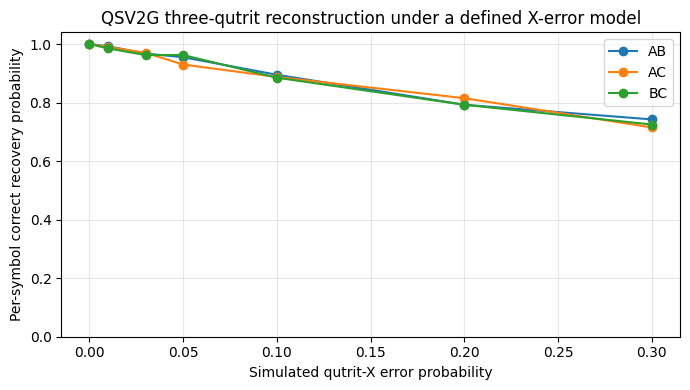

In [8]:
# Controlled qutrit-X channel errors (a Pauli-X shift on SECOND chosen share).
# This is NOT a depolarizing network, a malicious-dealer proof, or hardware fidelity.
noise_rates=[0,0.01,0.03,0.05,0.1,0.2,0.3]
noise_rng=np.random.default_rng(606)
noise_rows=[]
SHOTS=400
for pair in pairs:
  for rate in noise_rates:
    successful=0
    for i in range(SHOTS):
      s=int(noise_rng.integers(0,3))
      flipped=(noise_rng.random()<rate)
      xu,xv=measure_pair(qss_state(s),pair,noise_rng,x_fault=flipped)
      successful+=int(recover_symbol(pair,xu,xv)==s)
    noise_rows.append({'pair':''.join(pair),'x_error_rate':rate,'shots':SHOTS,
                       'successes':successful,'recovery_success_rate':successful/SHOTS,
                       'model':'single-share qutrit X error before computational measurement'})
noise_df=pd.DataFrame(noise_rows)
display(noise_df)
noise_df.to_csv(RESULTS/'qss_x_noise_recovery.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
for pair,g in noise_df.groupby('pair'):
    ax.plot(g.x_error_rate,g.recovery_success_rate,marker='o',label=pair)
ax.set(xlabel='Simulated qutrit-X error probability',ylabel='Per-symbol correct recovery probability',
       title='QSV2G three-qutrit reconstruction under a defined X-error model',ylim=(0,1.04))
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(RESULTS/'qss_x_noise_recovery.png',dpi=170)
plt.show()


## 8. End-to-end wall-clock timing and phase breakdown

End-to-end timing distribution (ms):


,count,mean,std,min,25%,50%,75%,max
total_wall_ms,8.0,164.955423,7.637684,156.852749,158.813885,163.293923,170.203837,177.667606


,phase,mean,std,min,max
0,authority_validation,0.088625,0.048267,0.057,0.202
1,authorization_token,36.132875,3.683358,31.454,43.462
2,context_agreement,0.247750,0.058029,0.193,0.357
3,cross_domain_authentication,0.166625,0.049263,0.126,0.237
4,energy_execution,0.153375,0.031924,0.129,0.228
5,ev_token_verification,15.378375,1.621305,13.640,18.196
6,qss_threshold,11.542000,0.961724,10.240,13.203
7,registration,18.088500,2.570562,15.916,23.205
8,session_establishment,30.874500,3.023546,27.379,36.188
9,termination,0.050750,0.002866,0.048,0.056


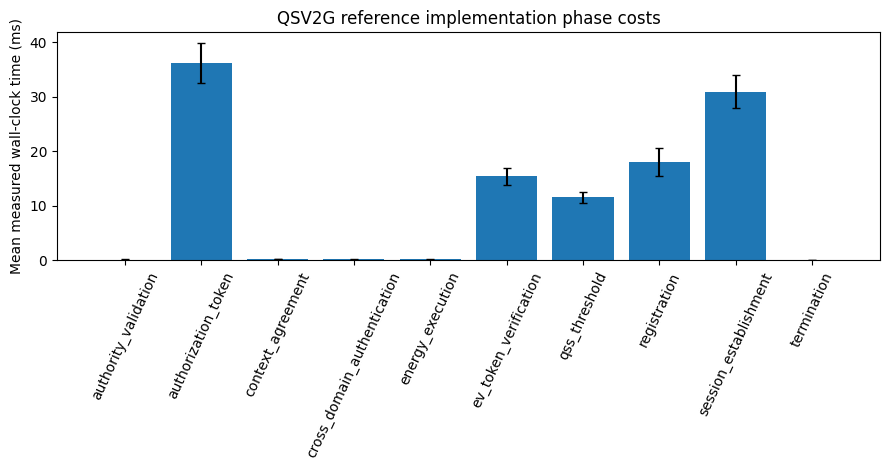

In [9]:
# End-to-end wall-clock benchmarks (measure simulator + Python crypto + backend overhead).
# These are NOT physical V2G, quantum-channel, or quantum-computer latencies.
N_RUNS=8
bench_rows=[]; phase_rows=[]
for trial in range(N_RUNS):
    start=time.perf_counter()
    b=run_demo(crypto=pqc,pair=pairs[trial%3],seed=700+trial,L=162)
    total=(time.perf_counter()-start)*1000
    assert b.stage=='TERMINATED'
    bench_rows.append({'trial':trial,'pair':''.join(pairs[trial%3]),'total_wall_ms':total,
                       'backend':pqc.kind,'L_trits':162})
    for item in b.log:
        phase_rows.append({'trial':trial,'phase':item['phase'],'elapsed_ms':item['elapsed_ms']})
bench_df=pd.DataFrame(bench_rows); phase_df=pd.DataFrame(phase_rows)
bench_df.to_csv(RESULTS/'qsv2g_end_to_end_timing.csv',index=False)
phase_df.to_csv(RESULTS/'qsv2g_phase_timing.csv',index=False)
print('End-to-end timing distribution (ms):')
display(bench_df[['total_wall_ms']].describe().T)
summary=phase_df.groupby('phase')['elapsed_ms'].agg(['mean','std','min','max']).reset_index()
display(summary)
summary.to_csv(RESULTS/'qsv2g_phase_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4.8))
ax.bar(summary.phase,summary['mean'],yerr=summary['std'].fillna(0),capsize=3)
ax.set(ylabel='Mean measured wall-clock time (ms)',title='QSV2G reference implementation phase costs')
ax.tick_params(axis='x',rotation=65)
fig.tight_layout(); fig.savefig(RESULTS/'qsv2g_phase_timings.png',dpi=170)
plt.show()


## 9. Communication accounting (actual AEAD wire packets; theoretical quantum counts)

In [10]:
# Report measured software packet sizes and modeled quantum resource counts.
# Counts exclude security-check sacrificial states, channel-control messages and hardware overhead.
comm_rows=[{'message':name,'wire_bytes':size} for name,size in sorted(last.wire_bytes.items())]
comm_df=pd.DataFrame(comm_rows)
assert len(comm_df)>=5
comm_df.to_csv(RESULTS/'qsv2g_classical_aead_packet_sizes.csv',index=False)
resource_df=pd.DataFrame([
 {'component':'EV Bell registration','quantum_transmissions':2*128,'unit':'qubit one-way transmissions'},
 {'component':'CS Bell registration','quantum_transmissions':2*128,'unit':'qubit one-way transmissions'},
 {'component':'three-dealer QSS resources, L=162','quantum_transmissions':6*162,'unit':'qutrit one-way transmissions'},
 {'component':'QSS qutrit subsystems stored collectively','quantum_transmissions':9*162,'unit':'qutrit subsystems'}
])
resource_df.to_csv(RESULTS/'qsv2g_quantum_resource_accounting.csv',index=False)
display(comm_df); display(resource_df)


,message,wire_bytes
0,authorization_response,9746
1,context_ack,239
2,context_offer,382
3,execution_start,265
4,termination,264


,component,quantum_transmissions,unit
0,EV Bell registration,256,qubit one-way transmissions
1,CS Bell registration,256,qubit one-way transmissions
2,"three-dealer QSS resources, L=162",972,qutrit one-way transmissions
3,QSS qutrit subsystems stored collectively,1458,qutrit subsystems


## 10. Results export / reproducibility manifest

In [11]:
# Export machine-readable run summary and a ZIP for review.
import zipfile, subprocess, importlib.metadata, platform
source_sha256='4ca43b1f6debd2e2bf314ff9adf74f0ad08ba1702e1055eca1943b9533290ef2'
manifest={
 'protocol_source':'QSV2G_main8_SectionIV_Revised.tex',
 'protocol_sha256':source_sha256,
 'model':'ideal 27D qutrit statevectors + single-share X-channel noise, no hardware',
 'backend':pqc.kind,
 'python':sys.version,
 'platform':platform.platform(),
 'numpy':np.__version__,
 'qiskit':(importlib.metadata.version('qiskit') if importlib.util.find_spec('qiskit') else None),
 'pennylane':(importlib.metadata.version('pennylane') if importlib.util.find_spec('pennylane') else None),
 'cryptography':importlib.metadata.version('cryptography'),
 'qss_L':162,
 'm_bell_pairs':128,
 'test_count':len(failure_df),
 'tests_passed':bool(failure_df['pass'].all()),
 'qss_pairs_correct':bool((quantum_df.success_rate==1).all()),
 'benchmark_runs':N_RUNS,
 'security_limitations':[
   'No malicious-secure verifiable QSS proof or dishonest-dealer simulation',
   'UC-A and UC-B online dependencies remain in the prescribed authentication flow',
   'QSS signs authority attestations; EV does not cryptographically verify quantum reconstruction itself',
   'In-memory authenticated channels, quantum memories, secure provisioning and meters are simulated assumptions',
   'Timing metrics include Python and local post-quantum implementation/CLI overhead',
   'X-error model is not a real network noise/fidelity characterization',
   'Single-share privacy applies to reduced quantum states, not unconditional secrecy of public classical commitments'
 ]
}
(RESULTS/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
readme='QSV2G notebook research output. Metrics are simulator/software measurements, not deployed V2G results.\nUse manifest.json to identify algorithms, platform, protocol version and known limitations.\nqss_ideal_reconstruction.csv verifies 3 pairs x 3 ternary values; qss_x_noise_recovery.csv is a specified X-error model.\nqsv2g_failure_tests.csv contains expected and actual rejection/acceptance checks.\nqsv2g_end_to_end_timing.csv and qsv2g_phase_timing.csv measure local wall-clock implementation costs.\nDo not make security superiority or real-quantum hardware claims based on these plots.\n'
(RESULTS/'README.txt').write_text(readme)
zip_path=RESULTS.parent/'qsv2g_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(RESULTS.iterdir()):
        if f.is_file(): z.write(f,arcname=f.name)
print('RESULTS ZIP:',zip_path,'bytes:',zip_path.stat().st_size)
print('CSV files:',[f.name for f in RESULTS.glob('*.csv')])
print('RESULT: FULL DEMONSTRATION AND TESTS COMPLETED')


RESULTS ZIP: /mnt/data/qsv2g_results.zip bytes: 176707
CSV files: ['qsv2g_end_to_end_timing.csv', 'qss_ideal_reconstruction.csv', 'qsv2g_classical_aead_packet_sizes.csv', 'qsv2g_failure_tests.csv', 'qsv2g_phase_summary.csv', 'qss_x_noise_recovery.csv', 'qsv2g_quantum_resource_accounting.csv', 'qsv2g_all_pairs.csv', 'qsv2g_phase_timing.csv']
RESULT: FULL DEMONSTRATION AND TESTS COMPLETED


## What the experiment **cannot** establish

- **Quantum computation:** This notebook simulates *ideal qutrits and explicit X errors* in NumPy. It does **not** demonstrate 3-level quantum hardware, verified quantum channels, entanglement distribution latency, or a physically deployable QSS network. Optional Qiskit/PennyLane cells check the two-qubit Bell state only.
- **Verifiable QSS:** The paper's two stabilizer checks and secret-value commitments do not amount to a malicious-dealer-secure protocol; the notebook fails closed when a sample is modified but does not prove security against an adaptive malicious actor.
- **Authorization:** The EV verifies **two ML-DSA-65 signatures attesting** to the authority reconstruction decision; it cannot independently prove that a quantum measurement occurred.
- **Availability:** UC-C may be unavailable in an AB approval, but UC-A/UC-B remain dependencies for identity/consent and station authentication/proof collection.
- **Privacy and deployment:** The provisioned keys, long-term records, grid policies, metering, networking, and timestamp synchronization are simulated. Use true deployment instrumentation and threat models before claiming V2G readiness.

**Please share the generated `qsv2g_results.zip`** after Kaggle completes. The manifest and CSVs allow checking the paper's evaluation statements against real outputs.